# retina-06-multihead

**Multi-head defect prediction + Grad-CAM localisation.**

---

## BEFORE YOU RUN — inputs this notebook needs

### Attach these (Add Data / Add Model, right-hand panel)

| # | Artefact | Slug | What is taken from it |
|---|---|---|---|
| 1 | Synthetic degraded set | `retina-degraded` | `degraded/*.png` + `manifest_degraded.csv` (33,990 rows) |
| 2 | Trained CNN | `retina-models` | `effnet_b0_best.keras` — the Week 6 backbone |
| 3 | External datasets | `retina-external-512` | DeepDRiD sub-scores + IDRiD disease grades |

> If you saved the Week 6 model as a **Kaggle Model** rather than a Dataset, use
> **Add Model** for item 2. Cell 1 finds `effnet_b0_best.keras` either way.

### Settings

| Setting | Value | Why |
|---|---|---|
| **Accelerator** | **GPU (T4 ×1)** | One forward pass over ~36k images. On CPU this takes hours. |
| **Internet** | **OFF** | Nothing is downloaded — the backbone comes from your own Dataset, not from Google. |

### Roughly how long

| Step | Time |
|---|---|
| Cell 4 — cache embeddings | 15–25 min (the slow one) |
| Cells 5–7 — train + score heads | under 1 min |
| Cells 9–10 — external sets | 3 min |
| Cells 11–12 — Grad-CAM | 4–6 min |

**Run top to bottom. No edits needed.** Cell 1 stops immediately with a clear message
if anything is missing.

In [1]:
# ============================================================================
# CELL 1 - Setup, and fail loudly if an input is missing
# ============================================================================
import datetime, json, os, shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tqdm.auto import tqdm

AUTOTUNE = tf.data.AUTOTUNE
SEED     = 42
SIZE     = 224          # Week 6's ablation found 384 bought nothing. Do not change.
DEFECTS  = ["underexposed", "defocus", "obstruction", "off_centre"]
CLASSES  = ["Good", "Usable", "Reject"]
LAPVAR_CLARITY_BASELINE = 0.120   # Week 9 cell 11. The bar cell 9 must beat.

keras.utils.set_random_seed(SEED)


def resolve(slug, root=Path("/kaggle/input"), max_depth=3):
    for depth in range(1, max_depth + 1):
        hits = [p for p in root.glob("/".join(["*"] * (depth - 1) + [slug])) if p.is_dir()]
        if hits:
            return hits[0]
    raise FileNotFoundError(
        f"'{slug}' is not attached.\n"
        f"   -> Add Data in the right-hand panel, search '{slug}', Add."
    )


def find_file(name, root=Path("/kaggle/input")):
    """Locate one file whatever the mount layout - Dataset or Kaggle Model."""
    hits = sorted(root.rglob(name))
    if not hits:
        raise FileNotFoundError(
            f"'{name}' not found anywhere under /kaggle/input.\n"
            f"   -> Attach the dataset or model that contains it (Add Data / Add Model)."
        )
    if len(hits) > 1:
        print(f"   note: {len(hits)} copies of {name}; using {hits[0]}")
    return hits[0]


print("resolving inputs ...\n")
DEG        = resolve("retina-degraded")
DEG_IMAGES = DEG / "degraded"
EXTERNAL   = resolve("retina-external-512")
CKPT       = find_file("effnet_b0_best.keras")
DEG_MANIFEST = find_file("manifest_degraded.csv")
EXT_MANIFEST = EXTERNAL / "manifest_external_512.csv"

for label, p in [("degraded images", DEG_IMAGES), ("degraded manifest", DEG_MANIFEST),
                 ("week-6 checkpoint", CKPT), ("external images", EXTERNAL / "external_512"),
                 ("external manifest", EXT_MANIFEST)]:
    assert p.exists(), f"missing: {label} at {p}"
    print(f"  OK  {label:20s} {p}")

WORK    = Path("/kaggle/working")
FIGURES = WORK / "figures"
RESULTS = WORK / "results"
for d in (FIGURES, RESULTS):
    d.mkdir(exist_ok=True)

gpus = tf.config.list_physical_devices("GPU")
print(f"\nGPU: {gpus if gpus else 'NONE'}")
assert gpus, ("No GPU. Settings -> Accelerator -> GPU T4 x1, then re-run.\n"
              "Cell 4 takes hours on CPU.")
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")


def record(name, params, metrics, notes=""):
    payload = {"name": name,
               "when": datetime.datetime.now().isoformat(timespec="seconds"),
               "params": params, "metrics": metrics, "notes": notes}
    (RESULTS / f"{name}.json").write_text(json.dumps(payload, indent=2, default=str))
    print(f"recorded {name}")
    return payload


print("\nall inputs present - safe to run on")

resolving inputs ...

  OK  degraded images      /kaggle/input/datasets/izuchukwuoruche/retina-degraded/degraded
  OK  degraded manifest    /kaggle/input/datasets/izuchukwuoruche/retina-degraded/manifest_degraded.csv
  OK  week-6 checkpoint    /kaggle/input/datasets/izuchukwuoruche/retina-models/effnet_b0_best.keras
  OK  external images      /kaggle/input/datasets/izuchukwuoruche/retina-external-512/external_512
  OK  external manifest    /kaggle/input/datasets/izuchukwuoruche/retina-external-512/manifest_external_512.csv

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
TensorFlow 2.20.0 | Keras 3.13.2

all inputs present - safe to run on


In [2]:
# ============================================================================
# CELL 2 - Load Week 6, build the embedder, grab the feature map
# ============================================================================
w6 = keras.models.load_model(CKPT, compile=False)

print("loaded model structure:")
for i, l in enumerate(w6.layers):
    print(f"  {i:2d}  {l.name:28s} {l.__class__.__name__:22s} -> {tuple(l.output.shape)}")

# Grab pooling by TYPE, not name - Keras auto-names it and the suffix varies.
try:
    gap = next(l for l in w6.layers
               if isinstance(l, keras.layers.GlobalAveragePooling2D))
except StopIteration:
    raise RuntimeError(
        "No GlobalAveragePooling2D layer. You have probably loaded the wrong "
        "checkpoint - 'phase1.keras' or 'effnet_b0_384.keras' instead of "
        "'effnet_b0_best.keras'. Check the layer list above."
    )

embedder = keras.Model(w6.inputs, gap.output, name="embedder")
EMB_DIM  = int(embedder.output.shape[-1])

# gap.input IS the last conv feature map, already wired into the outer graph.
# Reaching into the nested efficientnetb0 sub-model for it is fiddly; this is not.
# Cell 11 (Grad-CAM) needs it.
feature_map = gap.input

print(f"\nembedding dim       : {EMB_DIM}            (expect 1280)")
print(f"feature map (CAM)   : {tuple(feature_map.shape)}  (expect (None, 7, 7, 1280))")
assert EMB_DIM == 1280, f"unexpected embedding dim {EMB_DIM}"
assert len(feature_map.shape) == 4, "feature map is not spatial - graph differs from Week 6"
print(f"gradability head    : {tuple(w6.outputs[0].shape)}  (expect (None, 3))")

I0000 00:00:1791921733.049446      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791921733.052557      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


loaded model structure:
   0  input_layer_2                InputLayer             -> (None, 224, 224, 3)
   1  efficientnetb0               Functional             -> (None, 7, 7, 1280)
   2  global_average_pooling2d_1   GlobalAveragePooling2D -> (None, 1280)
   3  dropout_1                    Dropout                -> (None, 1280)
   4  dense_1                      Dense                  -> (None, 3)

embedding dim       : 1280            (expect 1280)
feature map (CAM)   : (None, 7, 7, 1280)  (expect (None, 7, 7, 1280))
gradability head    : (None, 3)  (expect (None, 3))


In [3]:
# ============================================================================
# CELL 3 - Patient-disjoint split of the synthetic set
# ============================================================================
from sklearn.model_selection import GroupShuffleSplit

deg = pd.read_csv(DEG_MANIFEST)
print(f"{len(deg):,} rows | {deg.patient_id.nunique():,} patients")
print(deg[DEFECTS].describe().round(3))

# sanity: Week 9 wrote 33,990 rows, each defect non-zero in ~40% of them
for d in DEFECTS:
    nz = (deg[d] > 0).mean()
    print(f"  {d:14s} non-zero in {nz:5.1%}   mean severity when present "
          f"{deg.loc[deg[d] > 0, d].mean():.2f}")


def group_split(df, frac, seed=SEED):
    gss = GroupShuffleSplit(n_splits=1, test_size=frac, random_state=seed)
    a, b = next(gss.split(df, groups=df.patient_id))
    return df.iloc[a].reset_index(drop=True), df.iloc[b].reset_index(drop=True)


dtrain, dtemp = group_split(deg, 0.30)
dval, dtest   = group_split(dtemp, 0.50)

print()
for name, part in [("train", dtrain), ("val", dval), ("test", dtest)]:
    print(f"  {name:5s} {len(part):6,d} images  {part.patient_id.nunique():5,d} patients")

# THE check. Five copies of one source image are five correlated images; one
# patient on both sides inflates every number that follows.
pt = {n: set(p.patient_id) for n, p in
      [("train", dtrain), ("val", dval), ("test", dtest)]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = pt[a] & pt[b]
    print(f"  {a} n {b}: {len(overlap)} shared patients")
    assert not overlap, f"PATIENT LEAK between {a} and {b} - stop here"

split_map = pd.concat([dtrain.assign(split="train"),
                       dval.assign(split="val"),
                       dtest.assign(split="test")])
split_map.to_csv(WORK / "manifest_degraded_split.csv", index=False)
print(f"\nfrozen -> manifest_degraded_split.csv  ({len(split_map):,} rows)")

33,990 rows | 4,365 patients
       underexposed    defocus  obstruction  off_centre
count     33990.000  33990.000    33990.000   33990.000
mean          0.250      0.249        0.250       0.249
std           0.335      0.335        0.334       0.335
min           0.000      0.000        0.000       0.000
25%           0.000      0.000        0.000       0.000
50%           0.000      0.000        0.000       0.000
75%           0.532      0.531        0.531       0.528
max           1.000      1.000        1.000       1.000
  underexposed   non-zero in 40.2%   mean severity when present 0.62
  defocus        non-zero in 39.7%   mean severity when present 0.63
  obstruction    non-zero in 40.2%   mean severity when present 0.62
  off_centre     non-zero in 39.9%   mean severity when present 0.62

  train 23,850 images  3,055 patients
  val    5,040 images    655 patients
  test   5,100 images    655 patients
  train n val: 0 shared patients
  train n test: 0 shared patients
  val n t

In [4]:
# ============================================================================
# CELL 4 - Cache the embeddings  [THE SLOW CELL: 15-25 min]
# ============================================================================
# The backbone is frozen, so its output for a given image never changes.
# Compute once, reuse for every later experiment.

def decode(path, size=SIZE):
    """Identical to Week 6's decode. float32 in [0, 255] - NOT normalised.
    EfficientNet has rescaling built in as its first layer."""
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (size, size), method="area")
    return tf.cast(img, tf.float32)


def embed(filenames, image_dir, batch=64):
    """Returns embeddings in the SAME ORDER as `filenames`.

    deterministic=True is load-bearing: parallel map without it may reorder,
    which would silently decouple every embedding from its label.
    """
    paths = np.array([str(image_dir / f) for f in filenames])
    ds = (tf.data.Dataset.from_tensor_slices(paths)
          .map(lambda p: decode(p), num_parallel_calls=AUTOTUNE, deterministic=True)
          .batch(batch).prefetch(AUTOTUNE))
    return embedder.predict(ds, verbose=1)


# No augmentation here, and that is deliberate.
# Week 6 used hflip + rot90. rot90 is WRONG for defect heads: obstruction always
# enters from the top, and rotating teaches the model it has no preferred
# direction - which also destroys cell 12's localisation check.
for name, part in [("train", dtrain), ("val", dval), ("test", dtest)]:
    out = WORK / f"emb_{name}.npy"
    # Resumable: if a previous run in this session already wrote a correctly
    # sized cache, reuse it. This cell is the expensive one; a session that
    # died at cell 9 should not pay for it twice.
    if out.exists():
        cached = np.load(out, mmap_mode="r")
        if cached.shape == (len(part), EMB_DIM):
            print(f"  {name:5s} {cached.shape}  cached, skipping")
            continue
        print(f"  {name:5s} cache is {cached.shape}, expected "
              f"{(len(part), EMB_DIM)} - recomputing")
    emb = embed(part.filename, DEG_IMAGES).astype("float32")
    assert len(emb) == len(part), "embedding count != row count"
    np.save(out, emb)
    print(f"  {name:5s} {emb.shape}  {emb.nbytes / 1e6:5.0f} MB")

print("\nembeddings cached")

2026-10-13 20:02:28.307013: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:02:28.464092: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:02:28.874170: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:02:29.018048: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:02:29.826918: E external/local_xla/xla/stream_

372/373 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step

2026-10-13 20:04:00.842724: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:00.990767: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:01.358491: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:01.501387: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:02.269764: E external/local_xla/xla/stream_

373/373 ━━━━━━━━━━━━━━━━━━━━ 108s 248ms/step
  train (23850, 1280)    122 MB
78/79 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step

2026-10-13 20:04:29.483011: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:29.632763: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:30.014796: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:30.157170: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:30.926629: E external/local_xla/xla/stream_

79/79 ━━━━━━━━━━━━━━━━━━━━ 28s 357ms/step
  val   (5040, 1280)     26 MB
79/80 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step

2026-10-13 20:04:58.171654: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:58.319836: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:58.708794: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:58.851591: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:04:59.634591: E external/local_xla/xla/stream_

80/80 ━━━━━━━━━━━━━━━━━━━━ 29s 357ms/step
  test  (5100, 1280)     26 MB

embeddings cached


In [5]:
# ============================================================================
# CELL 5 - The defect heads (two models, SHARED layer objects)
# ============================================================================
def make_heads(emb_dim, n_defects=len(DEFECTS), hidden=0, dropout=0.3, seed=SEED):
    """Returns (head_model, layers).

    `layers` is reused in cell 8 to build the full image->defects model.
    Calling a Keras layer on a second input makes a new graph node but keeps
    the SAME weights - which is exactly what we want, and is why cell 8 needs
    no retraining.
    """
    keras.utils.set_random_seed(seed)
    layers = [keras.layers.Dropout(dropout, name="defect_drop")]
    if hidden:
        layers += [keras.layers.Dense(hidden, activation="relu", name="defect_hidden"),
                   keras.layers.Dropout(dropout, name="defect_drop2")]
    layers.append(keras.layers.Dense(n_defects, activation="sigmoid", name="defects"))

    emb_in = keras.Input(shape=(emb_dim,), name="emb")
    x = emb_in
    for l in layers:
        x = l(x)
    m = keras.Model(emb_in, x, name="defect_head")
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m, layers


# sigmoid + MSE, not a classifier: the target is a severity in [0,1], and a
# bounded regression output reads directly as a severity. Thresholding it also
# gives presence/absence, so one head serves both uses.
probe, probe_layers = make_heads(EMB_DIM, hidden=0)
print(f"linear probe params: {probe.count_params():,}   "
      f"(expect {EMB_DIM * len(DEFECTS) + len(DEFECTS):,})")
probe.summary()

linear probe params: 5,124   (expect 5,124)


Model: "defect_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ emb (InputLayer)                │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ defect_drop (Dropout)           │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ defects (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,124 (20.02 KB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# ============================================================================
# CELL 6 - Train, and compare a linear probe against an MLP
# ============================================================================
Xtr, Xva, Xte = (np.load(WORK / f"emb_{s}.npy") for s in ("train", "val", "test"))
ytr, yva, yte = (p[DEFECTS].values.astype("float32") for p in (dtrain, dval, dtest))

def cbs():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                          restore_best_weights=True, verbose=0),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                              patience=4, min_lr=1e-6, verbose=0)]

# val_loss is the right monitor here, unlike Week 6. There, training loss was
# class-weighted and validation loss was not, so the two measured different
# things. Here both are plain MSE over four balanced regression targets.
print("training linear probe ...")
probe.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=200, batch_size=256, callbacks=cbs(), verbose=0)

print("training 256-unit MLP ...")
mlp, mlp_layers = make_heads(EMB_DIM, hidden=256)
mlp.fit(Xtr, ytr, validation_data=(Xva, yva),
        epochs=200, batch_size=256, callbacks=cbs(), verbose=0)

mse_probe = probe.evaluate(Xva, yva, verbose=0)[0]
mse_mlp   = mlp.evaluate(Xva, yva, verbose=0)[0]
print(f"\n  linear probe  val MSE {mse_probe:.5f}   ({probe.count_params():,} params)")
print(f"  256-unit MLP  val MSE {mse_mlp:.5f}   ({mlp.count_params():,} params)")

# THE COMPARISON IS THE RESULT, not a hyperparameter search:
#   probe ~= MLP  -> defect identity is LINEARLY encoded in the gradability
#                    features. The stronger, more interesting claim.
#   MLP better    -> the information is there but entangled.
rel = (mse_probe - mse_mlp) / mse_probe
if rel < 0.05:
    head, head_layers, which = probe, probe_layers, "linear"
    print(f"\n  -> MLP improves val MSE by only {rel:+.1%}. Keeping the LINEAR PROBE:"
          f"\n     defect identity is linearly encoded in the gradability features.")
else:
    head, head_layers, which = mlp, mlp_layers, "mlp256"
    print(f"\n  -> MLP improves val MSE by {rel:+.1%}. Keeping the MLP:"
          f"\n     the information is present but needs a non-linear read-out.")

training linear probe ...
training 256-unit MLP ...

  linear probe  val MSE 0.01141   (5,124 params)
  256-unit MLP  val MSE 0.00623   (328,964 params)

  -> MLP improves val MSE by +45.4%. Keeping the MLP:
     the information is present but needs a non-linear read-out.


      defect  n_present  MAE_all  MAE_present  AUC_presence
underexposed       2089    0.067        0.130         0.990
     defocus       1949    0.025        0.052         0.999
 obstruction       2062    0.034        0.060         0.995
  off_centre       2023    0.041        0.083         0.996

mean AUC_presence: 0.995

HOW TO READ THIS
  MAE_all is the number that will lie to you. ~60% of every severity column is
  exactly 0, so a head predicting a flat 0.0 scores MAE_all ~ 0.25 and looks
  respectable while being useless.

  AUC_presence is the honest headline - threshold-free, immune to the zero
  inflation. MAE_present is the honest severity number.

    > 0.90   strong
    0.80-0.90  usable; expected for subtler defects at low severity
    0.65-0.80  weak - say which defect and why
    ~ 0.50   learned nothing -> suspect label alignment before the model



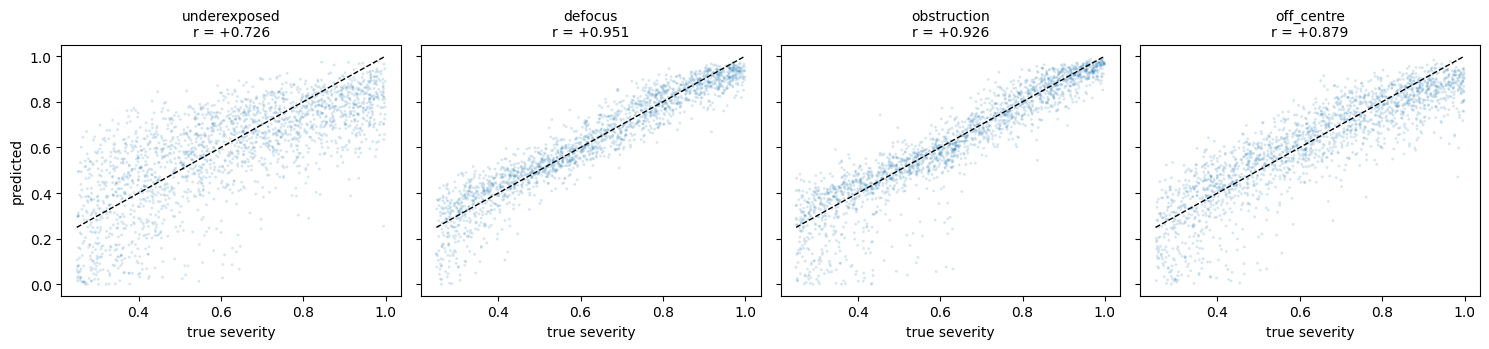

recorded w10-defect-heads


{'name': 'w10-defect-heads',
 'when': '2026-10-13T20:06:33',
 'params': {'backbone': 'effnet_b0_best (frozen)',
  'size': 224,
  'head': 'mlp256',
  'loss': 'mse',
  'emb_dim': 1280,
  'val_mse_probe': 0.011409291066229343,
  'val_mse_mlp': 0.006225698161870241},
 'metrics': {'per_defect': [{'defect': 'underexposed',
    'n_present': 2089,
    'MAE_all': 0.067,
    'MAE_present': 0.13,
    'AUC_presence': 0.99},
   {'defect': 'defocus',
    'n_present': 1949,
    'MAE_all': 0.025,
    'MAE_present': 0.052,
    'AUC_presence': 0.999},
   {'defect': 'obstruction',
    'n_present': 2062,
    'MAE_all': 0.034,
    'MAE_present': 0.06,
    'AUC_presence': 0.995},
   {'defect': 'off_centre',
    'n_present': 2023,
    'MAE_all': 0.041,
    'MAE_present': 0.083,
    'AUC_presence': 0.996}],
  'mean_auc': 0.995},
 'notes': 'heads trained on cached embeddings; synthetic patient-disjoint test split'}

In [7]:
# ============================================================================
# CELL 7 - Metrics, and the trap in them
# ============================================================================
from sklearn.metrics import mean_absolute_error, roc_auc_score

pred = head.predict(Xte, batch_size=512, verbose=0)
assert len(pred) == len(dtest), "prediction/label row mismatch"

rows = []
for i, d in enumerate(DEFECTS):
    present = yte[:, i] > 0
    auc = (roc_auc_score(present, pred[:, i])
           if 0 < present.sum() < len(present) else float("nan"))
    rows.append({"defect": d,
                 "n_present": int(present.sum()),
                 "MAE_all": mean_absolute_error(yte[:, i], pred[:, i]),
                 "MAE_present": mean_absolute_error(yte[present, i], pred[present, i]),
                 "AUC_presence": auc})
res = pd.DataFrame(rows).round(3)
print(res.to_string(index=False))
print(f"\nmean AUC_presence: {res.AUC_presence.mean():.3f}")

print("""
HOW TO READ THIS
  MAE_all is the number that will lie to you. ~60% of every severity column is
  exactly 0, so a head predicting a flat 0.0 scores MAE_all ~ 0.25 and looks
  respectable while being useless.

  AUC_presence is the honest headline - threshold-free, immune to the zero
  inflation. MAE_present is the honest severity number.

    > 0.90   strong
    0.80-0.90  usable; expected for subtler defects at low severity
    0.65-0.80  weak - say which defect and why
    ~ 0.50   learned nothing -> suspect label alignment before the model
""")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=True, sharey=True)
for ax, (i, d) in zip(axes, enumerate(DEFECTS)):
    m = yte[:, i] > 0
    ax.scatter(yte[m, i], pred[m, i], s=4, alpha=0.18, edgecolors="none")
    ax.plot([0.25, 1], [0.25, 1], "k--", lw=1)
    r = np.corrcoef(yte[m, i], pred[m, i])[0, 1]
    ax.set_title(f"{d}\nr = {r:+.3f}", fontsize=10)
    ax.set_xlabel("true severity")
axes[0].set_ylabel("predicted")
plt.tight_layout(); plt.savefig(FIGURES / "severity_scatter.png", dpi=150); plt.show()

record("w10-defect-heads",
       {"backbone": "effnet_b0_best (frozen)", "size": SIZE, "head": which,
        "loss": "mse", "emb_dim": EMB_DIM,
        "val_mse_probe": float(mse_probe), "val_mse_mlp": float(mse_mlp)},
       {"per_defect": res.to_dict("records"),
        "mean_auc": float(res.AUC_presence.mean())},
       notes="heads trained on cached embeddings; synthetic patient-disjoint test split")

In [8]:
# ============================================================================
# CELL 8 - Graft the heads onto the full model
# ============================================================================
# Image in -> gradability (3-way softmax) + four defect severities.
x = gap.output                 # the pooled vector already in the graph
for l in head_layers:
    x = l(x)                   # SAME layer objects -> already trained

defect_out = x                 # named handles. cell 11 needs defect_out.
grad_out   = w6.outputs[0]

multihead = keras.Model(inputs=w6.inputs,
                        outputs={"gradability": grad_out, "defects": defect_out},
                        name="retina_multihead")
print(f"gradability: {tuple(grad_out.shape)}   defects: {tuple(defect_out.shape)}")

# ---------------------------------------------------------------------------
# KERAS REORDERS DICT OUTPUTS ALPHABETICALLY AND WILL NOT WARN YOU.
#   multihead.outputs[0] -> defects      (4 units)
#   multihead.outputs[1] -> gradability  (3 units)
# The reverse of what is written above. This fails SILENTLY: index 1 expecting
# defects returns the gradability head, pred[:, 1] is a valid column of a 3-unit
# softmax, and every shape checks out - you would produce a Grad-CAM of the
# "Usable" class and label it "defocus".
# ALWAYS index by key. Never by position.
# ---------------------------------------------------------------------------
for i, t in enumerate(multihead.outputs):
    print(f"  multihead.outputs[{i}] has {t.shape[-1]} units "
          f"-> {'defects' if t.shape[-1] == len(DEFECTS) else 'gradability'}")

# Verify the graft rather than trusting it: both paths must give one answer.
chk = dtest.filename.head(64)
a = head.predict(embed(chk, DEG_IMAGES), verbose=0)
ds_chk = (tf.data.Dataset.from_tensor_slices(
            np.array([str(DEG_IMAGES / f) for f in chk]))
          .map(lambda p: decode(p), num_parallel_calls=AUTOTUNE, deterministic=True)
          .batch(64))
out = multihead.predict(ds_chk, verbose=0)
b = out["defects"] if isinstance(out, dict) else out[0]

diff = float(np.abs(a - b).max())
print(f"\ngraft equivalence: max abs difference = {diff:.2e}   (expect 0.00e+00)")
assert diff < 1e-4, ("graft failed - make_heads was called again between training "
                     "and grafting, so these are fresh random layers")
print("graft verified")

# Save the deliverable NOW, not at the end. Everything after this point is
# evaluation and figures; none of it should be able to cost you the model.
multihead.save(WORK / "retina_multihead.keras")
print(f"saved retina_multihead.keras "
      f"({os.path.getsize(WORK / 'retina_multihead.keras') / 1e6:.1f} MB)")

gradability: (None, 3)   defects: (None, 4)
  multihead.outputs[0] has 4 units -> defects
  multihead.outputs[1] has 3 units -> gradability
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 635ms/step

graft equivalence: max abs difference = 1.19e-07   (expect 0.00e+00)
graft verified
saved retina_multihead.keras (18.4 MB)


In [9]:
# ============================================================================
# CELL 9 - Does it transfer to REAL degradation?  [the result that matters]
# ============================================================================
# The backbone has never seen DeepDRiD, and DeepDRiD carries real human
# sub-scores. Direction conventions, both confirmed in Week 9:
#     clarity   higher = BETTER  -> predicted defocus should correlate NEGATIVELY
#     artifact  higher = WORSE   -> predicted obstruction should correlate POSITIVELY
from scipy.stats import spearmanr

ext = pd.read_csv(EXT_MANIFEST)
print("datasets in manifest:", sorted(ext.dataset.unique()))

dd = ext[ext.dataset == "deepdrid"].dropna(subset=["clarity", "artifact"])
print(f"{len(dd):,} DeepDRiD images with real sub-scores")
assert len(dd) > 100, "too few DeepDRiD rows with sub-scores - check the manifest"

emb_dd  = embed(dd.filename, EXTERNAL / "external_512")
pred_dd = pd.DataFrame(head.predict(emb_dd, verbose=0), columns=DEFECTS)
pred_dd["clarity"]  = dd.clarity.values
pred_dd["artifact"] = dd.artifact.values

pairs = [("defocus", "clarity", "negative"),
         ("obstruction", "artifact", "positive"),
         ("underexposed", "clarity", "negative"),
         ("off_centre", "artifact", "positive")]

print(f"\n{'predicted':14s} {'vs real':10s} {'pearson':>9s} {'spearman':>9s}  expect     sign")
transfer = {}
for d, real, expect in pairs:
    p = float(pred_dd[d].corr(pred_dd[real]))
    s = float(spearmanr(pred_dd[d], pred_dd[real]).statistic)
    ok = "OK" if ((p < 0) == (expect == "negative")) else "WRONG SIGN"
    print(f"{d:14s} {real:10s} {p:+9.3f} {s:+9.3f}  {expect:9s}  {ok}")
    transfer[f"{d}_vs_{real}"] = {"pearson": p, "spearman": s, "expected": expect}

# Spearman alongside Pearson because the sub-scores are coarse ordinals: a
# monotone-but-non-linear relationship is the realistic expectation, and
# Pearson understates it.

# ---- THE BAR, set in advance from Week 9 ----
got = abs(pred_dd["defocus"].corr(pred_dd["clarity"]))
print(f"\n{'='*66}")
print(f"  learned defocus head vs real Clarity : |{got:.3f}|")
print(f"  classical lap_var baseline (Week 9)  : |{LAPVAR_CLARITY_BASELINE:.3f}|")
if got > LAPVAR_CLARITY_BASELINE:
    print(f"  -> BEATS the baseline by {got - LAPVAR_CLARITY_BASELINE:+.3f}."
          f"\n     The synthetic training taught the CNN something a classical"
          f"\n     sharpness statistic does not capture.")
else:
    print(f"  -> DOES NOT beat the baseline ({got - LAPVAR_CLARITY_BASELINE:+.3f})."
          f"\n     Report this honestly: on this measure the synthetic data added"
          f"\n     nothing beyond what lap_var already gave for free.")
print(f"{'='*66}")

record("w10-deepdrid-transfer",
       {"n": int(len(dd)), "lap_var_baseline": LAPVAR_CLARITY_BASELINE, "head": which},
       {"correlations": transfer, "defocus_vs_clarity_abs": float(got),
        "beats_baseline": bool(got > LAPVAR_CLARITY_BASELINE)})

datasets in manifest: ['deepdrid', 'drimdb', 'fqs', 'idrid']
1,600 DeepDRiD images with real sub-scores
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 261ms/step

predicted      vs real      pearson  spearman  expect     sign
defocus        clarity       -0.469    -0.469  negative   OK
obstruction    artifact      +0.307    +0.390  positive   OK
underexposed   clarity       -0.283    -0.213  negative   OK
off_centre     artifact      +0.066    +0.106  positive   OK

  learned defocus head vs real Clarity : |0.469|
  classical lap_var baseline (Week 9)  : |0.120|
  -> BEATS the baseline by +0.349.
     The synthetic training taught the CNN something a classical
     sharpness statistic does not capture.
recorded w10-deepdrid-transfer


{'name': 'w10-deepdrid-transfer',
 'when': '2026-10-13T20:06:47',
 'params': {'n': 1600, 'lap_var_baseline': 0.12, 'head': 'mlp256'},
 'metrics': {'correlations': {'defocus_vs_clarity': {'pearson': -0.46894940959476844,
    'spearman': -0.4693221558449372,
    'expected': 'negative'},
   'obstruction_vs_artifact': {'pearson': 0.30688310100777394,
    'spearman': 0.3900651646409199,
    'expected': 'positive'},
   'underexposed_vs_clarity': {'pearson': -0.28348095618919644,
    'spearman': -0.2130392812719392,
    'expected': 'negative'},
   'off_centre_vs_artifact': {'pearson': 0.06644307629563109,
    'spearman': 0.10569541255221439,
    'expected': 'positive'}},
  'defocus_vs_clarity_abs': 0.46894940959476844,
  'beats_baseline': True},
 'notes': ''}

In [10]:
# ============================================================================
# CELL 10 - The pathology control  [the safety test]
# ============================================================================
# A screening tool that calls diseased retinas ungradable is worse than useless:
# it would reject exactly the patients who need grading. IDRiD is good-quality
# images graded for disease severity.
#
# The failure mode is NOT a high overall Reject rate. It is a Reject rate that
# RISES WITH DISEASE GRADE.
idrid = ext[(ext.dataset == "idrid")].dropna(subset=["dr_grade"])
print(f"{len(idrid):,} IDRiD images with DR grades")
assert len(idrid) > 50, "too few IDRiD rows - check the manifest"

ds_id = (tf.data.Dataset.from_tensor_slices(
            np.array([str(EXTERNAL / "external_512" / f) for f in idrid.filename]))
         .map(lambda p: decode(p), num_parallel_calls=AUTOTUNE, deterministic=True)
         .batch(64).prefetch(AUTOTUNE))
out_id = multihead.predict(ds_id, verbose=1)
grad_logits = out_id["gradability"] if isinstance(out_id, dict) else out_id[1]
grad_pred   = grad_logits.argmax(axis=1)
reject_prob = grad_logits[:, 2]

print("\npredicted gradability on a pathology set:")
for c, n in zip(CLASSES, np.bincount(grad_pred, minlength=3)):
    print(f"  {c:7s} {n:4d}  {n / len(grad_pred):6.1%}")

ctrl = pd.DataFrame({"dr_grade": idrid.dr_grade.astype(int).values,
                     "pred": grad_pred, "reject_prob": reject_prob})
tab = ctrl.groupby("dr_grade").agg(n=("pred", "size"),
                                   reject_rate=("pred", lambda s: (s == 2).mean()),
                                   mean_reject_prob=("reject_prob", "mean")).round(3)
print("\nreject rate by DR grade - this must NOT climb:")
print(tab.to_string())

trend = float(spearmanr(ctrl.dr_grade, ctrl.reject_prob).statistic)
print(f"\nSpearman(DR grade, P(Reject)) = {trend:+.3f}")
print("""
  ~ 0 or negative  -> CLEAN. The model separates image quality from pathology.
                      A strong sentence for the report.
  clearly positive -> REAL PROBLEM. Pathology is being read as a defect.
                      State it plainly as the main limitation; do not bury it.
  high but flat    -> domain shift, not pathology confusion. Week 11's territory.
""")

record("w10-idrid-pathology-control",
       {"n": int(len(idrid))},
       {"class_rates": {c: float((grad_pred == i).mean()) for i, c in enumerate(CLASSES)},
        "reject_by_grade": tab.reject_rate.to_dict(),
        "spearman_grade_vs_reject_prob": trend})

516 IDRiD images with DR grades
8/9 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step

2026-10-13 20:06:56.521725: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:06:56.656566: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:06:56.974852: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:06:57.116838: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:06:57.900701: E external/local_xla/xla/stream_

9/9 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step

predicted gradability on a pathology set:
  Good     280   54.3%
  Usable   204   39.5%
  Reject    32    6.2%

reject rate by DR grade - this must NOT climb:
            n  reject_rate  mean_reject_prob
dr_grade                                    
0         168        0.036             0.041
1          25        0.000             0.001
2         168        0.065             0.078
3          93        0.043             0.065
4          62        0.177             0.217

Spearman(DR grade, P(Reject)) = +0.481

  ~ 0 or negative  -> CLEAN. The model separates image quality from pathology.
                      A strong sentence for the report.
  clearly positive -> REAL PROBLEM. Pathology is being read as a defect.
                      State it plainly as the main limitation; do not bury it.
  high but flat    -> domain shift, not pathology confusion. Week 11's territory.

recorded w10-idrid-pathology-control


{'name': 'w10-idrid-pathology-control',
 'when': '2026-10-13T20:07:01',
 'params': {'n': 516},
 'metrics': {'class_rates': {'Good': 0.5426356589147286,
   'Usable': 0.3953488372093023,
   'Reject': 0.06201550387596899},
  'reject_by_grade': {0: 0.036, 1: 0.0, 2: 0.065, 3: 0.043, 4: 0.177},
  'spearman_grade_vs_reject_prob': 0.4810328246065111},
 'notes': ''}

In [11]:
# ============================================================================
# CELL 10b - Disentangle the pathology finding
# ============================================================================
# Cell 10 showed P(Reject) rising with DR grade. Before calling that a failure,
# rule out the two innocent explanations. There are three possibilities:
#
#   (1) the gradability head reads LESIONS as image defects      <- the real failure
#   (2) advanced DR genuinely produces harder-to-grade images    <- the model is right
#       (vitreous haemorrhage clouds the media; cataract is commoner in
#        long-standing diabetes; fixation is poorer)
#   (3) IDRiD's camera/population differs from EyeQ's            <- domain shift
#
# Remember IDRiD's "good quality" label is an assumption WE made when building
# the external manifest, not an IDRiD annotation. That matters here.

# ---- A. Do the DEFECT heads explain the trend? ----
emb_id = embed(idrid.filename, EXTERNAL / "external_512")
sev_id = pd.DataFrame(head.predict(emb_id, verbose=0), columns=DEFECTS)
sev_id["dr_grade"]    = idrid.dr_grade.astype(int).values
sev_id["reject_prob"] = reject_prob

print("mean predicted severity by DR grade:")
print(sev_id.groupby("dr_grade")[DEFECTS + ["reject_prob"]].mean().round(3).to_string())

print("\ncorrelation of DR grade with each predicted severity:")
defect_trend = {}
for d in DEFECTS:
    r = float(spearmanr(sev_id.dr_grade, sev_id[d]).statistic)
    defect_trend[d] = r
    print(f"  Spearman(DR grade, predicted {d:14s}) = {r:+.3f}")
strongest = max(defect_trend, key=lambda k: defect_trend[k])
print(f"\n  reject_prob trend was {trend:+.3f}; "
      f"strongest defect trend is {strongest} at {defect_trend[strongest]:+.3f}")
if trend < 0.15:
    print("""
  -> There is no meaningful Reject trend with DR grade to explain. The control
     is clean on this measure: report it as evidence the model separates image
     quality from pathology.""")
elif defect_trend[strongest] > 0.6 * trend:
    print(f"""
  -> The defect heads MOVE WITH the Reject trend ({strongest} at
     {defect_trend[strongest]:+.3f} against {trend:+.3f}). That is consistent
     with explanation (2): the model is reporting a real image problem in
     advanced disease rather than reacting to lesions directly. Check the named
     defect is physically plausible - defocus or underexposure would be;
     off-centre would not, and would weaken this reading.""")
else:
    print(f"""
  -> The Reject trend ({trend:+.3f}) is NOT explained by any defect head
     (strongest is {strongest} at {defect_trend[strongest]:+.3f}). That points
     at explanation (1): the gradability head is reacting to the lesions
     themselves. This is the dangerous reading, and it belongs in the report as
     the headline limitation rather than buried.""")

# ---- B. Is it disease, or is it just this camera? ----
# Baseline: Reject rate on GOOD-quality images from datasets with no DR-grade
# confound. If those are elevated too, part of this is domain shift (3).
print("\nReject rate on good-quality images, by dataset:")
base_rates = {}
for ds in ["drimdb", "fqs", "idrid"]:
    sub = ext[(ext.dataset == ds) & (ext.quality == 0)].dropna(subset=["filename"])
    if len(sub) < 20:
        print(f"  {ds:9s} only {len(sub)} good-quality rows - skipped")
        continue
    d_ = (tf.data.Dataset.from_tensor_slices(
            np.array([str(EXTERNAL / "external_512" / f) for f in sub.filename]))
          .map(lambda p: decode(p), num_parallel_calls=AUTOTUNE, deterministic=True)
          .batch(64).prefetch(AUTOTUNE))
    o_ = multihead.predict(d_, verbose=0)
    g_ = (o_["gradability"] if isinstance(o_, dict) else o_[1]).argmax(axis=1)
    rate = float((g_ == 2).mean())
    base_rates[ds] = {"n": int(len(sub)), "reject_rate": rate}
    print(f"  {ds:9s} n={len(sub):5d}   Reject {rate:6.1%}")

others = [v["reject_rate"] for k, v in base_rates.items() if k != "idrid"]
if others and "idrid" in base_rates:
    print(f"""
  IDRiD {base_rates['idrid']['reject_rate']:.1%} vs other good-quality external
  sets {min(others):.1%}-{max(others):.1%}. If IDRiD is not an outlier, the
  overall rate is domain shift and the GRADE TREND is the finding worth
  reporting - not the level.""")

record("w10-pathology-diagnostic",
       {"n_idrid": int(len(idrid))},
       {"reject_prob_trend": trend,
        "defect_trends_vs_grade": defect_trend,
        "good_quality_reject_rates": base_rates},
       notes="disentangles lesion-confusion from genuine media opacity and domain shift")

9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 678ms/step
mean predicted severity by DR grade:
          underexposed  defocus  obstruction  off_centre  reject_prob
dr_grade                                                             
0                0.087    0.006        0.019       0.037        0.041
1                0.033    0.003        0.019       0.036        0.001
2                0.082    0.032        0.030       0.058        0.078
3                0.064    0.038        0.029       0.047        0.065
4                0.110    0.074        0.052       0.063        0.217

correlation of DR grade with each predicted severity:
  Spearman(DR grade, predicted underexposed  ) = +0.079
  Spearman(DR grade, predicted defocus       ) = +0.516
  Spearman(DR grade, predicted obstruction   ) = +0.267
  Spearman(DR grade, predicted off_centre    ) = +0.113

  reject_prob trend was +0.481; strongest defect trend is defocus at +0.516

  -> The defect heads MOVE WITH the Reject trend (defocus at
     +0.516 agai

2026-10-13 20:07:14.675615: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:14.833706: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:15.327548: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:15.470145: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:15.612025: E external/local_xla/xla/stream_

  drimdb    n=  125   Reject  16.0%


2026-10-13 20:07:26.939624: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:27.073800: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:27.401080: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:27.542853: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:28.290305: E external/local_xla/xla/stream_

  fqs       n=  514   Reject   0.8%
  idrid     n=  516   Reject   6.2%

  IDRiD 6.2% vs other good-quality external
  sets 0.8%-16.0%. If IDRiD is not an outlier, the
  overall rate is domain shift and the GRADE TREND is the finding worth
  reporting - not the level.
recorded w10-pathology-diagnostic


{'name': 'w10-pathology-diagnostic',
 'when': '2026-10-13T20:07:33',
 'params': {'n_idrid': 516},
 'metrics': {'reject_prob_trend': 0.4810328246065111,
  'defect_trends_vs_grade': {'underexposed': 0.07896437858449391,
   'defocus': 0.5164900007367675,
   'obstruction': 0.2672060983519588,
   'off_centre': 0.11296782176512388},
  'good_quality_reject_rates': {'drimdb': {'n': 125, 'reject_rate': 0.16},
   'fqs': {'n': 514, 'reject_rate': 0.007782101167315175},
   'idrid': {'n': 516, 'reject_rate': 0.06201550387596899}}},
 'notes': 'disentangles lesion-confusion from genuine media opacity and domain shift'}

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step

2026-10-13 20:07:39.867655: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:40.009433: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:40.358043: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:40.500596: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:07:41.279686: E external/local_xla/xla/stream_

10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step


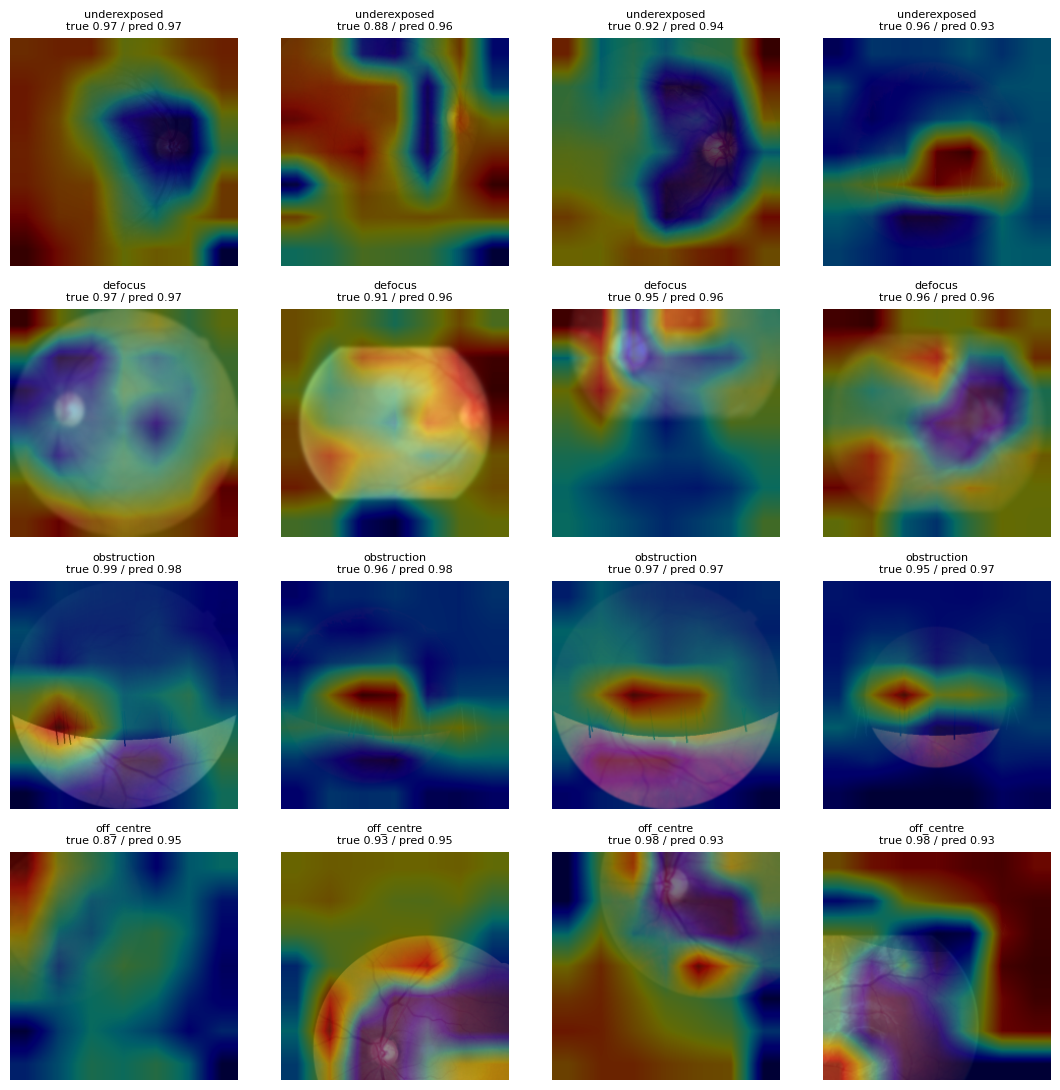

saved gradcam_by_defect.png - this is the most useful figure in the project


In [12]:
# ============================================================================
# CELL 11 - Where: Grad-CAM  (no spatial labels needed)
# ============================================================================
# Which regions of the last conv feature map, if changed, would most change this
# head's output? Gradient of the head w.r.t. the feature map, averaged per
# channel for channel importances, then a weighted sum of channels.
#
# defect_out, NOT multihead.outputs[1] - see the ordering warning in cell 8.
cam_model = keras.Model(w6.inputs, [feature_map, defect_out], name="cam_model")


CAM_BATCH = 16   # GradientTape retains every intermediate activation for the
                 # backward pass, so this is FAR more memory-hungry than a
                 # predict() at the same batch size. 120 at once OOMs a T4
                 # (it dies on a (120, 14, 14, 480) tensor). 16 is safe and
                 # the result is numerically identical - verified.


def _cam_chunk(images, defect_index):
    x = tf.convert_to_tensor(images, dtype=tf.float32)
    with tf.GradientTape() as tape:
        fmap, pred = cam_model(x, training=False)
        tape.watch(fmap)            # fmap is intermediate, not a variable.
        target = pred[:, defect_index]   # Without this, tape.gradient returns
                                         # None and einsum raises on a NoneType
                                         # nowhere near the real cause.
    grads = tape.gradient(target, fmap)
    if grads is None:
        raise RuntimeError("gradient is None - tape.watch(fmap) is missing or misplaced")
    weights = tf.reduce_mean(grads, axis=(1, 2))         # [B, C]
    cam = tf.nn.relu(tf.einsum("bhwc,bc->bhw", fmap, weights))
    return (cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)).numpy()


def grad_cam(images, defect_index, upsample=True, batch=CAM_BATCH):
    """images: float32 [B, SIZE, SIZE, 3] in [0, 255]. Chunked to fit GPU memory."""
    cams = np.concatenate([_cam_chunk(images[i:i + batch], defect_index)
                           for i in range(0, len(images), batch)], axis=0)
    if not upsample:
        return cams                                      # raw 7x7, for cell 12
    return tf.image.resize(cams[..., None], (SIZE, SIZE),
                           method="bilinear")[..., 0].numpy()


def load_batch(filenames):
    return np.stack([decode(str(DEG_IMAGES / f)).numpy() for f in filenames])


# RESOLUTION LIMIT, and say it in the report: at 224 px the feature map is 7x7,
# so each cell covers a 32x32 px block. Enough to say "the top of the image is
# obstructed"; not enough to trace an eyelid margin.
N_CAM = min(600, len(dtest))
try:
    sample = dtest.sample(N_CAM, random_state=SEED).reset_index(drop=True)
    emb_s  = embed(sample.filename, DEG_IMAGES)
    pred_s = head.predict(emb_s, verbose=0)

    fig, axes = plt.subplots(len(DEFECTS), 4, figsize=(11, 11))
    for r, (i, d) in enumerate(zip(range(len(DEFECTS)), DEFECTS)):
        cand = sorted(sample.index[sample[d] > 0.6].tolist(), key=lambda j: -pred_s[j, i])[:4]
        if not cand:
            for c in range(4):
                axes[r, c].axis("off")
            continue
        imgs = load_batch(sample.filename[cand])
        cams = grad_cam(imgs, i)
        for c, (j, im, cm) in enumerate(zip(cand, imgs, cams)):
            axes[r, c].imshow(im.astype("uint8"))
            axes[r, c].imshow(cm, cmap="jet", alpha=0.42)
            axes[r, c].set_title(f"{d}\ntrue {sample[d][j]:.2f} / pred {pred_s[j, i]:.2f}",
                                 fontsize=8)
            axes[r, c].axis("off")
        for c in range(len(cand), 4):
            axes[r, c].axis("off")
    plt.tight_layout(); plt.savefig(FIGURES / "gradcam_by_defect.png", dpi=150); plt.show()
    print("saved gradcam_by_defect.png - this is the most useful figure in the project")
except Exception as e:
    # A figure is a presentation artefact. Do not let it cost you the whole
    # committed run - the model, the heads and the results all matter more.
    print(f"!! Grad-CAM figure failed: {type(e).__name__}: {e}")
    print("   continuing. Lower CAM_BATCH and re-run this cell if you want the figure.")


In [13]:
# ============================================================================
# CELL 12 - Does the CAM look in the right place?
# ============================================================================
# Eyeballing heat maps lets you believe whatever you hoped. But the generator
# KNOWS where it put each defect, so we have free localisation ground truth.
#
# obstruction always enters from the TOP, reaching 0.12 + 0.48*severity down the
# frame. The top 3 rows of a 7x7 grid are 3/7 ~ 0.43 of the area, so an
# unlocalised CAM scores ~0.43 and a correctly localised one scores well above.
NULL = 3 / 7

def top_mass(cams_7x7, rows=3):
    tot = cams_7x7.sum(axis=(1, 2)) + 1e-8
    return cams_7x7[:, :rows, :].sum(axis=(1, 2)) / tot


loc = {}
try:
    print(f"null expectation if the model has no spatial preference: {NULL:.3f}\n")
    loc = {}
    for i, d in enumerate(DEFECTS):
        cand = sample.index[sample[d] > 0.6].tolist()[:120]
        if not cand:
            print(f"  {d:14s} no high-severity examples in the sample")
            continue
        # measured on the RAW 7x7 grid, so 3 rows is exactly 3/7 by construction
        tm = top_mass(grad_cam(load_batch(sample.filename[cand]), i, upsample=False))
        loc[d] = {"mean": float(tm.mean()), "std": float(tm.std()), "n": len(cand)}
        flag = "LOCALISED" if tm.mean() > NULL + 0.08 else (
               "flat" if abs(tm.mean() - NULL) <= 0.08 else "below null")
        print(f"  {d:14s} top-third CAM mass {tm.mean():.3f} +/- {tm.std():.3f}  "
              f"(n={len(cand)})  {flag}")

    print(f"""
    WHAT YOU WANT TO SEE - and one flat row IS a success

      obstruction   well ABOVE {NULL:.2f}  the lid is at the top; the CAM should follow it
      defocus       ~ {NULL:.2f}           blur is global. There is no "where".
                                    A flat score is the model being CORRECT.
      underexposed  ~ {NULL:.2f}           also global
      off_centre    ~ {NULL:.2f}           direction is random per image, so it averages out

    The result is the CONTRAST: localisation concentrates for the defect that has a
    location and stays flat for the one that does not. A CAM that localised defocus
    to one corner would be the warning sign, not a flat one.
    """)

    record("w10-cam-localisation",
           {"grid": 7, "rows": 3, "null": NULL, "severity_threshold": 0.6,
            "measured_on": "raw 7x7 grid"},
           loc)
except Exception as e:
    print(f"!! localisation check failed: {type(e).__name__}: {e}")
    print("   lower CAM_BATCH and re-run this cell.")


null expectation if the model has no spatial preference: 0.429

  underexposed   top-third CAM mass 0.409 +/- 0.107  (n=120)  flat
  defocus        top-third CAM mass 0.426 +/- 0.060  (n=114)  flat
  obstruction    top-third CAM mass 0.412 +/- 0.105  (n=120)  flat
  off_centre     top-third CAM mass 0.447 +/- 0.163  (n=116)  flat

    WHAT YOU WANT TO SEE - and one flat row IS a success

      obstruction   well ABOVE 0.43  the lid is at the top; the CAM should follow it
      defocus       ~ 0.43           blur is global. There is no "where".
                                    A flat score is the model being CORRECT.
      underexposed  ~ 0.43           also global
      off_centre    ~ 0.43           direction is random per image, so it averages out

    The result is the CONTRAST: localisation concentrates for the defect that has a
    location and stays flat for the one that does not. A CAM that localised defocus
    to one corner would be the warning sign, not a flat one.
    
re

In [14]:
# ---- optional: make Week 12 self-contained (run before Save & Run All) ----
CAMSET = WORK / "cam_eval"
CAMSET.mkdir(exist_ok=True)
keep = []
for d in DEFECTS:
    for fn in sample.filename[sample[d] > 0.6].head(120):
        shutil.copy(DEG_IMAGES / fn, CAMSET / fn)
        keep.append({"filename": fn, "defect": d, **{k: float(sample.loc[sample.filename == fn, k].iloc[0]) for k in DEFECTS}})
pd.DataFrame(keep).drop_duplicates("filename").to_csv(WORK / "manifest_cam_eval.csv", index=False)
print(f"{len(list(CAMSET.iterdir())):,} images -> cam_eval/  "
      f"({sum(p.stat().st_size for p in CAMSET.iterdir())/1e6:.0f} MB)")

340 images -> cam_eval/  (49 MB)


In [15]:
# ============================================================================
# CELL 13 - Save, clean, and list exactly what to publish
# ============================================================================
multihead.save(WORK / "retina_multihead.keras")
mb = os.path.getsize(WORK / "retina_multihead.keras") / 1e6

for junk in [".virtual_documents"]:
    shutil.rmtree(WORK / junk, ignore_errors=True)

print(f"retina_multihead.keras   {mb:5.1f} MB")
print("""
   Note: Week 6's checkpoint reported 47.9 MB. This is smaller because that
   number included Adam optimizer state (2 extra values per parameter) which
   inference does not need. THIS is the real starting point for compression.
""")

print("files to publish:")
for p in sorted(WORK.iterdir()):
    if p.is_dir():
        print(f"   {p.name + '/':34s} {len(list(p.iterdir()))} files")
    else:
        print(f"   {p.name:34s} {p.stat().st_size / 1e6:7.1f} MB")

print()
!du -sh /kaggle/working
!df -h /kaggle/working

print(f"""
{'='*70}
SUMMARY FOR VERIFICATION - paste this block back to me
{'='*70}
head chosen            : {which}  (probe val MSE {mse_probe:.5f} / mlp {mse_mlp:.5f})
mean AUC_presence      : {res.AUC_presence.mean():.3f}
graft equivalence      : {diff:.2e}
defocus vs Clarity     : {got:+.3f}   (baseline {LAPVAR_CLARITY_BASELINE}, beats = {got > LAPVAR_CLARITY_BASELINE})
IDRiD grade vs Reject  : {trend:+.3f}
model size             : {mb:.1f} MB
{'='*70}""")

retina_multihead.keras    18.4 MB

   Note: Week 6's checkpoint reported 47.9 MB. This is smaller because that
   number included Adam optimizer state (2 extra values per parameter) which
   inference does not need. THIS is the real starting point for compression.

files to publish:
   __notebook__.ipynb                     1.4 MB
   cam_eval/                          340 files
   emb_test.npy                          26.1 MB
   emb_train.npy                        122.1 MB
   emb_val.npy                           25.8 MB
   figures/                           2 files
   manifest_cam_eval.csv                  0.0 MB
   manifest_degraded_split.csv            2.8 MB
   results/                           5 files
   retina_multihead.keras                18.4 MB

237M	/kaggle/working
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  237M   20G   2% /kaggle/working

SUMMARY FOR VERIFICATION - paste this block back to me
head chosen            : mlp256  (probe val MSE 0.01

---

## AFTER IT RUNS — outputs to save

### 1 · Publish as a new Kaggle Dataset

**Save Version → Save & Run All → Output tab → New Dataset**, named exactly:

```
retina-multihead
```

It will contain:

| File / folder | Size | Why it is kept |
|---|---|---|
| `retina_multihead.keras` | ~17 MB | **The deliverable.** Gradability + 4 defect heads in one model. |
| `emb_train.npy`, `emb_val.npy`, `emb_test.npy` | ~174 MB | Cached embeddings. Keeping these saves a 20-minute GPU pass every time you revisit the heads. |
| `manifest_degraded_split.csv` | ~3 MB | The frozen patient-disjoint split. Re-splitting later would move every number for no reason. |
| `results/w10-*.json` | tiny | Four versioned result records — defect heads, DeepDRiD transfer, pathology control, localisation. |
| `figures/severity_scatter.png` | | Report figure. |
| `figures/gradcam_by_defect.png` | | Report figure — the best one in the project. |

### 2 · Paste the SUMMARY block back to me

Cell 13 prints a `SUMMARY FOR VERIFICATION` block. Send me that, plus anything that
errored or looked odd. I will check it before you start Week 11.

### 3 · Then Week 11 attaches

`retina-multihead` + `retina-external-512` + `retina-results`.

---

### If something goes wrong

| Symptom | Cause |
|---|---|
| Cell 1 raises `FileNotFoundError` | That dataset is not attached. The message names it. |
| Cell 1 asserts on GPU | Settings → Accelerator → GPU T4 ×1 |
| Cell 2 `RuntimeError: No GlobalAveragePooling2D` | Wrong checkpoint — you have `effnet_b0_384.keras` or `phase1.keras`, not `effnet_b0_best.keras` |
| Cell 3 asserts `PATIENT LEAK` | Stop. Every later number would be meaningless. Send me the output. |
| Cell 8 asserts graft failed | `make_heads` ran again between training and grafting |
| Every `AUC_presence` ≈ 0.50 | Label/prediction row order came apart — send me cell 7's output |
| Out of memory in cell 4 | Lower `batch=64` to `32` in the `embed(...)` call |

**Do not fix a failing assertion by removing it.** Send me the output instead — each
one is there because the thing it checks fails silently otherwise.